# CoMETs Tutorial: Population Latent Encoder + Unit Identity Encoder

This notebook walks through the full two-stage CoMETs pipeline on a real mouse hippocampal dataset.

**Stage 1 — Latent encoder:** learns a population-level latent trajectory `Z [T, D]` from synchronized LFP + spikes using temporal contrastive learning (InfoNCE). `Z[t]` captures what the population is doing at time `t`.

**Stage 2 — Unit encoder:** freezes the latent encoder, then learns a geometry over neuron identity `E [N, d_u]`. Each neuron gets a stationary embedding. Neurons that tend to co-fire under similar population states are pulled together.

The two stages train sequentially. Firing rates and the frozen latent enter only as **loss gates** — they never enter the representation itself.

---
Dataset: CRCNS `ec013.157` — mouse hippocampus, linear track, theta-band LFP + spike data.

## 0. Setup

In [1]:
import os, pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys

from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from scipy.ndimage import gaussian_filter1d
from scipy.stats import spearmanr

import torch

# --- find the directory that directly contains the comets package ---
# Walk up from cwd until we find a folder with comets/__init__.py.
# comets_test1/ contains comets/ directly, so it is found before the
# parent code/ directory (which contains the original comets package).
for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (p / "comets" / "__init__.py").exists():
        if str(p) not in sys.path:
            sys.path.insert(0, str(p))
        break

# Evict any previously cached comets from a prior kernel run
for mod in list(sys.modules):
    if mod == "comets" or mod.startswith("comets."):
        del sys.modules[mod]

import comets
from comets import (
    ModalityConfig, SamplingConfig,
    LatentTrainingConfig, UnitTrainingConfig,
    CEBRASKipEncoder, SkippedConvEncoderConfig,
    LinearHead,
    train_latent, train_unit,
)
from comets.unit_eval import (
    ratemap_correlation,
    place_cell_enrichment,
    split_half_stability,
    nn_purity,
)

print("Imports OK")
print(f"  comets loaded from: {comets.__file__}")

Imports OK
  comets loaded from: /mnt/d/comets/code/comets_test1/comets/__init__.py


In [2]:
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

CUDA available: True
GPU: NVIDIA RTX 2000 Ada Generation


## 1. Load Data

In [3]:
session = "ec013.157"

cwd = Path.cwd().resolve()
repo_root = next(
    (p for p in [cwd, *cwd.parents] if (p / "data" / "crcns_mouse").exists()), None
)
load_path = repo_root / "data" / "crcns_mouse" / session / f"{session}_lfp_spike.pkl"

with open(load_path, "rb") as f:
    data = pickle.load(f)

print(f"Loaded: {load_path}")
print(f"Available keys: {sorted(data.keys())}")

# --- unpack ---
# lfp_theta_50hz: theta-band LFP already downsampled to fs_common (50 Hz)  [T, 65]
# lfp_theta:      theta-band LFP at native fs_lfp (1250 Hz) — NOT used here
lfp_theta_full   = np.asarray(data["lfp_theta_50hz"]).astype(np.float32)   # [T, 65]
spike_count_full = np.asarray(data["spike_bin"])                           # [T, N]  counts per 20 ms bin
spike_rate_full  = np.asarray(data["spike_rate"])                          # [T, N]  Hz
position_full    = np.asarray(data["position_50hz"])                       # [T] or [T, 2]
fs_common        = data["fs_common"]
bin_size_ms      = data["bin_size_ms_spike"]
track_mode       = data.get("track_mode", "linear")

# Remove artefact channel 65 from LFP
lfp_theta_full = lfp_theta_full[:, :-1]   # [T, 64]

# For linear tracks, position_50hz is 1D.  For 2D arenas it is [T, 2].
# The tutorial uses 1D position (ec013.157 is linear).
if position_full.ndim == 2:
    position_full = position_full[:, 0]    # take x-coordinate if 2D

print(f"Track mode: {track_mode}")
print(f"LFP (theta 50Hz): {lfp_theta_full.shape}   fs={fs_common} Hz")
print(f"Spikes (counts):  {spike_count_full.shape}   bin={bin_size_ms} ms")
print(f"Position:         {position_full.shape}")

Loaded: /mnt/d/comets/data/crcns_mouse/ec013.157/ec013.157_lfp_spike.pkl
Available keys: ['bin_size_ms_spike', 'fs_common', 'fs_lfp', 'head_direction', 'lfp_raw', 'lfp_theta', 'lfp_theta_50hz', 'position_50hz', 'position_raw', 'session', 'session_dir', 'speed', 'spike_bin', 'spike_bin_smoothed', 'spike_rate', 'spike_raw', 'theta_band', 'track_mode']
Track mode: linear
LFP (theta 50Hz): (31560, 64)   fs=50 Hz
Spikes (counts):  (31560, 80)   bin=20 ms
Position:         (31560,)


## 2. Preprocessing + Region of Interest

We select a contiguous ROI to keep training fast for this tutorial. In practice, train on the full session.

In [4]:
window_start = 100
window_end   = 15100      # 15 000 time bins = 300 s at 50 Hz

spike_count_roi = spike_count_full[window_start:window_end].astype(np.float32)   # [T, N]
spike_rate_roi  = spike_rate_full[window_start:window_end].astype(np.float32)    # [T, N]  Hz
lfp_roi         = lfp_theta_full[window_start:window_end].astype(np.float32)     # [T, C]
position_roi    = position_full[window_start:window_end]                          # [T]

# normalize spike rates to [0, 1] per neuron — used for Stage 1 embedding input
rmin = spike_rate_roi.min(axis=0, keepdims=True)
rmax = spike_rate_roi.max(axis=0, keepdims=True)
spike_norm_roi = (spike_rate_roi - rmin) / (rmax - rmin + 1e-9)   # [T, N]  Stage 1 input

T, N = spike_count_roi.shape
_, C = lfp_roi.shape

print(f"ROI: [{window_start}, {window_end}]  →  T={T} bins  ({T/fs_common:.0f} s)")
print(f"N = {N} neurons,  C = {C} LFP channels")

# color code for visualizations: time → viridis
color_code = np.linspace(0, 1, T)

ROI: [100, 15100]  →  T=15000 bins  (300 s)
N = 80 neurons,  C = 64 LFP channels


## 3. Utility Functions

In [5]:
def reduce_to_3d(Z):
    """PCA to 3D for visualization."""
    Z = np.asarray(Z)
    if Z.shape[1] > 3:
        Z = PCA(n_components=3).fit_transform(Z)
    return Z[:, 0], Z[:, 1], Z[:, 2]


def ridge_decode(Z, y, train_frac=0.7, alpha=1.0):
    """Ridge regression decoding.  Returns (mean_euclidean_test, y_pred_test, n_train)."""
    Z = np.asarray(Z)
    y = np.asarray(y)
    ntr = int(train_frac * len(Z))
    reg = Ridge(alpha=alpha).fit(Z[:ntr], y[:ntr])
    yhat = reg.predict(Z[ntr:])
    err  = np.mean(np.abs(y[ntr:] - yhat))     # mean absolute error (1-D position)
    return err, yhat, ntr


def compute_ratemaps(spike_counts, position, n_bins=40, sigma=2.0):
    """
    Occupancy-normalized spatial rate maps for each neuron.

    Parameters
    ----------
    spike_counts : [T, N]  raw spike counts per bin
    position     : [T]     linearized position
    n_bins       : number of spatial bins
    sigma        : Gaussian smoothing width (bins)

    Returns
    -------
    ratemaps : [N, n_bins]  firing rate (Hz) at each position bin
    centers  : [n_bins]     bin center positions
    """
    edges    = np.linspace(position.min(), position.max(), n_bins + 1)
    centers  = 0.5 * (edges[:-1] + edges[1:])
    pos_bins = np.clip(np.digitize(position, edges) - 1, 0, n_bins - 1)

    # occupancy in seconds
    occ = np.bincount(pos_bins, minlength=n_bins) / fs_common   # [n_bins]

    N  = spike_counts.shape[1]
    rm = np.zeros((N, n_bins))
    for i in range(N):
        spk = np.bincount(pos_bins, weights=spike_counts[:, i], minlength=n_bins)
        rm[i] = spk / (occ + 1e-9)

    rm = gaussian_filter1d(rm, sigma=sigma, axis=1)
    return rm, centers


def identify_place_cells(ratemaps, min_peak_hz=1.0, peak_mean_ratio=3.0):
    """
    Simple place-cell heuristic: peak rate exceeds threshold AND
    peak-to-mean ratio exceeds threshold (focused tuning).

    Returns boolean array [N].
    """
    peak = ratemaps.max(axis=1)
    mean = ratemaps.mean(axis=1)
    ratio = peak / (mean + 1e-9)
    return (peak >= min_peak_hz) & (ratio >= peak_mean_ratio)


print("Utility functions defined.")

Utility functions defined.


---
## Stage 1 — Latent Population Encoder

**Goal:** learn a smooth latent trajectory `Z [T, D]` that captures the state of the neural population at each time bin.

**How it works:**
- Two modalities: spikes `[T, N]` and theta-band LFP `[T, C]`.
- Each modality has its own encoder (1D residual conv) + projection head.
- Loss: temporal InfoNCE — time bins close in time should have similar embeddings; temporally distant bins should be pushed apart.
- No behavioral label is used. The model learns purely from the temporal structure of neural activity.

**Input:** `spike_norm_roi` (normalized firing rates) and `lfp_roi` (raw theta LFP).

**Output:** `latent_model` — a trained `CoMETsModel` object.

In [6]:
# --- Modality A: spikes [T, N] ---
modA = ModalityConfig(
    encoder_cls = CEBRASKipEncoder,
    encoder_cfg = SkippedConvEncoderConfig(
        in_channels = N,     # number of neurons
        emb_dim     = 32,    # encoder output dimension
        hidden      = 64,
        num_blocks  = 3,
    ),
    win_len = 8,             # temporal context window (bins)
)

# --- Modality B: LFP [T, C] ---
modB = ModalityConfig(
    encoder_cls = CEBRASKipEncoder,
    encoder_cfg = SkippedConvEncoderConfig(
        in_channels = C,     # number of LFP channels
        emb_dim     = 16,
        hidden      = 32,
        num_blocks  = 3,
    ),
    win_len = 8,
)

# --- Temporal sampling ---
# pos_offset: anchor and positive are this many bins apart (~100 ms at 50 Hz)
# negative_mask_dist: mask nearby bins as not-negatives (16 bins = 320 ms)
sampling = SamplingConfig(
    batch_size        = 256,
    pos_offset        = 5,
    negative_mask_dist= 16,
)

# --- Training hyperparameters ---
latent_cfg = LatentTrainingConfig(
    epochs      = 100,
    lr          = 1e-3,
    temperature = 1.0,
    proj_dim    = 8,         # dimension of the latent projection Z
    alpha_cross = 0.1,       # weight of cross-modality loss
    beta        = 0.8,       # spike-modality weight in within-modality loss
    head_cls    = LinearHead,
)

print("Stage 1 config ready.")
print(f"  Latent dimension: {latent_cfg.proj_dim}")
print(f"  Positive offset:  {sampling.pos_offset} bins = {sampling.pos_offset * bin_size_ms} ms")

Stage 1 config ready.
  Latent dimension: 8
  Positive offset:  5 bins = 100 ms


In [7]:
import time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Training device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('WARNING: CUDA not available — training will run on CPU and be ~10x slower.')
    print('         Switch to a GPU kernel in Jupyter (Kernel → Change kernel) if possible.')

# Quick single-step timing estimate
import numpy as np
_A = torch.randn(256, 8, N, device=device)
_B = torch.randn(256, 8, C, device=device)
# small conv as proxy
import torch.nn as nn
_enc = nn.Sequential(
    nn.Conv1d(N, 64, 2), nn.GELU(),
    nn.AdaptiveAvgPool1d(1),
).to(device)
if device.type == 'cuda':
    torch.cuda.synchronize()
_t0 = time.perf_counter()
for _ in range(10):
    _ = _enc(_A.transpose(1,2))
if device.type == 'cuda':
    torch.cuda.synchronize()
_elapsed = (time.perf_counter() - _t0) / 10
del _enc, _A, _B

steps_per_epoch = max(1, T // sampling.batch_size)
# rough estimate: 4 encoder paths, 4 losses, ~3x overhead for backward
_est_step_s = _elapsed * 4 * 3
_est_epoch_s = _est_step_s * steps_per_epoch
print(f'Estimated Stage 1 speed: ~{_est_epoch_s:.0f}s / epoch  'f'→  100 epochs ≈ {100*_est_epoch_s/60:.0f} min')

Training device: cuda
GPU: NVIDIA RTX 2000 Ada Generation
GPU memory: 17.2 GB
Estimated Stage 1 speed: ~9s / epoch  →  100 epochs ≈ 15 min


In [8]:
# Train!
# spike_norm_roi = [T, N] normalized firing rates  (modality A)
# lfp_roi        = [T, C] theta LFP                (modality B)

latent_model = train_latent(
    spike_norm_roi, modA,
    lfp_roi,        modB,
    sampling, latent_cfg,
)

print(f"\nlatent_model type: {type(latent_model).__name__}")

Stage 1: Latent Encoder: 100%|██████████| 100/100 [00:50<00:00,  1.98it/s, total=4.7674, within=4.7421, cross=4.9958, lr=0.00e+00]


latent_model type: CoMETsModel


### Embed the latent trajectory

The model has three embedding methods:

| Method | Input | Output | Use |
|---|---|---|---|
| `embed_latent_spikes(spikes)` | `[T, N]` | `[T, D]` | spike-modality embedding |
| `embed_latent_lfp(lfp)` | `[T, C]` | `[T, D]` | LFP-modality embedding |
| `embed_latent(spikes)` | `[T, N]` | `[T, D]` | shorthand for spike embedding; used as frozen context in Stage 2 |

In [9]:
Z_spikes = latent_model.embed_latent_spikes(spike_norm_roi)   # [T, D]
Z_lfp    = latent_model.embed_latent_lfp(lfp_roi)             # [T, D]

print(f"Z_spikes: {Z_spikes.shape}   Z_lfp: {Z_lfp.shape}")

# ridge decode position from each embedding
err_spk, _, ntr = ridge_decode(Z_spikes, position_roi)
err_lfp, _, _   = ridge_decode(Z_lfp,    position_roi)
print(f"\nRidge decoding (position, MAE):")
print(f"  Z_spikes: {err_spk:.2f}")
print(f"  Z_lfp:    {err_lfp:.2f}")
print(f"  (lower is better)")

Z_spikes: (15000, 8)   Z_lfp: (15000, 8)

Ridge decoding (position, MAE):
  Z_spikes: 53.24
  Z_lfp:    87.03
  (lower is better)


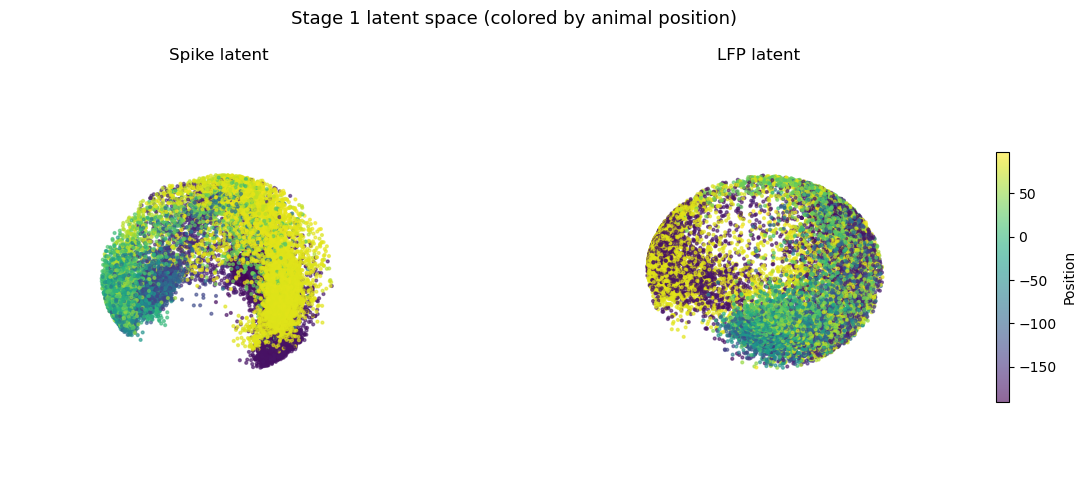

In [10]:
# --- Visualize latent space (PCA to 3D, colored by position) ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5), subplot_kw={'projection': '3d'})

for ax, Z, title in zip(axes, [Z_spikes, Z_lfp], ["Spike latent", "LFP latent"]):
    x, y, z = reduce_to_3d(Z)
    sc = ax.scatter(x, y, z, c=position_roi, cmap='viridis', s=4, alpha=0.6)
    ax.set_title(title, fontsize=12)
    ax.set_axis_off()

plt.colorbar(sc, ax=axes[1], label='Position', shrink=0.6)
fig.suptitle("Stage 1 latent space (colored by animal position)", fontsize=13)
plt.tight_layout()
plt.show()

---
## Stage 2 — Unit Identity Encoder

**Goal:** learn a stationary embedding `E [N, d_u]` for each of the N neurons, where neurons that are functionally similar (co-fire under similar population states) are geometrically close.

**Key design points:**
- `e_i` does not vary with time — it is a single vector per neuron.
- Firing rates and latent context enter only as **loss weights**, not as model input.
- Two loss terms run jointly:

**L_coact (co-activity loss)**
- At each step, sample M neurons and look up their spike counts at `t_anchor` and `t_pos` (a nearby time).
- Gate: `log(r_i+1) * log(r_j+1)`, batch-centered via relu — zero when either neuron is silent or below-average.
- Pull neurons with high joint activity together; the InfoNCE denominator pushes dissimilar pairs apart.

**L_ctx (context-conditioned loss)**
- Draw two independent banks of K diverse time windows.
- Gate: `log(r_i+1) * log(r_j+1)` × `cosine(Z[ctx_A[k]], Z[ctx_B[k]])` — requires co-firing AND similar latent context.
- This teaches the embedding about functional similarity across the whole session, not just nearby moments.

**Input for Stage 2:** `spike_count_roi` (raw counts, NOT normalized) — the log gate needs real firing rates to distinguish silence from activity.

In [11]:
unit_cfg = UnitTrainingConfig(
    epochs           = 100,
    lr               = 1e-3,
    d_u              = 8,     # unit embedding dimension
    m_units          = 32,    # neurons sampled per step per pool
    temperature      = 0.1,   # InfoNCE temperature
    lambda_coact     = 1.0,   # weight of co-activity loss
    lambda_ctx       = 1.0,   # weight of context-conditioned loss
    lambda_spike_ctx = 1.0,   # how much spike latent contributes to context sim
    lambda_lfp_ctx   = 1.0,   # how much LFP latent contributes to context sim
)

print("Stage 2 config ready.")
print(f"  Unit embedding dimension: {unit_cfg.d_u}")
print(f"  Units sampled per step:   {unit_cfg.m_units}  (2M = {2*unit_cfg.m_units} in coact pool)")

Stage 2 config ready.
  Unit embedding dimension: 8
  Units sampled per step:   32  (2M = 64 in coact pool)


In [12]:
# Train Stage 2.
#
# We pass:
#   latent_model  — frozen Stage 1 model (weights not updated)
#   spike_count_roi — raw spike counts [T, N]  (NOT normalized)
#   sampling      — same config as Stage 1 (batch_size = K context windows)
#   unit_cfg      — Stage 2 hyperparameters
#   lfp=lfp_roi   — LFP array for dual-modality context similarity
#                   (omit this argument to use spike context only)

unit_model = train_unit(
    latent_model,
    spike_count_roi,
    sampling,
    unit_cfg,
    lfp = lfp_roi,     # <-- include LFP context; set to None to skip
)

print(f"\nunit_model type: {type(unit_model).__name__}")

Stage 2: Unit Encoder: 100%|██████████| 100/100 [00:25<00:00,  3.86it/s, loss=2.5803, lr=0.00e+00]


unit_model type: UnitEncoder


In [13]:
# Extract unit embeddings.
# .embeddings() returns [N, d_u] as a CPU tensor (no grad).

E = unit_model.embeddings().numpy()   # [N, d_u]

print(f"Unit embedding matrix E: {E.shape}")
print(f"  Each row = one neuron's stationary identity vector.")
print(f"  Norms: min={np.linalg.norm(E, axis=1).min():.3f}  "
      f"max={np.linalg.norm(E, axis=1).max():.3f}  (should be ~1.0, L2-normalized)")

Unit embedding matrix E: (80, 8)
  Each row = one neuron's stationary identity vector.
  Norms: min=1.000  max=1.000  (should be ~1.0, L2-normalized)


---
## Evaluating the Unit Embedding Space

We have E `[N, d_u]` — one vector per neuron. Now we ask: **did the model learn anything meaningful?**

We will use four metrics from `comets.unit_eval`:

| Metric | Question |
|---|---|
| `ratemap_correlation` | Do neurons close in E have similar spatial tuning? |
| `place_cell_enrichment` | Are place cells geometrically clustered in E? |
| `split_half_stability` | Is E consistent if we train on two halves of the session? |
| `nn_purity` | Do nearest neighbors in E share the same cell type? |

We will also compare against a **random baseline** (untrained `nn.Embedding`).

In [14]:
import torch
import torch.nn.functional as F

# Random baseline: same architecture, random weights, never trained
torch.manual_seed(42)
E_random = F.normalize(
    torch.randn(N, unit_cfg.d_u), dim=-1
).numpy()   # [N, d_u]

print(f"Baseline E_random: {E_random.shape}  (random unit vectors, untrained)")

Baseline E_random: (80, 8)  (random unit vectors, untrained)


### Rate Map Correlation

A **rate map** shows how much a neuron fires at each position on the track. If two neurons have similar rate maps, they prefer the same locations.

`ratemap_correlation(E, ratemaps)` computes:
1. Pairwise Euclidean distances between all neuron pairs in E.
2. Pairwise cosine distances between all neuron pairs' rate maps.
3. Spearman correlation between the two distance vectors.

**Positive ρ is good:** neurons that are close in E (small embedding distance) also have similar rate maps (small ratemap distance). This would mean the embedding has captured spatial tuning geometry.

Rate maps: (80, 40)  (80 neurons × 40 position bins)
Peak firing rates: min=0.00  max=85.96 Hz


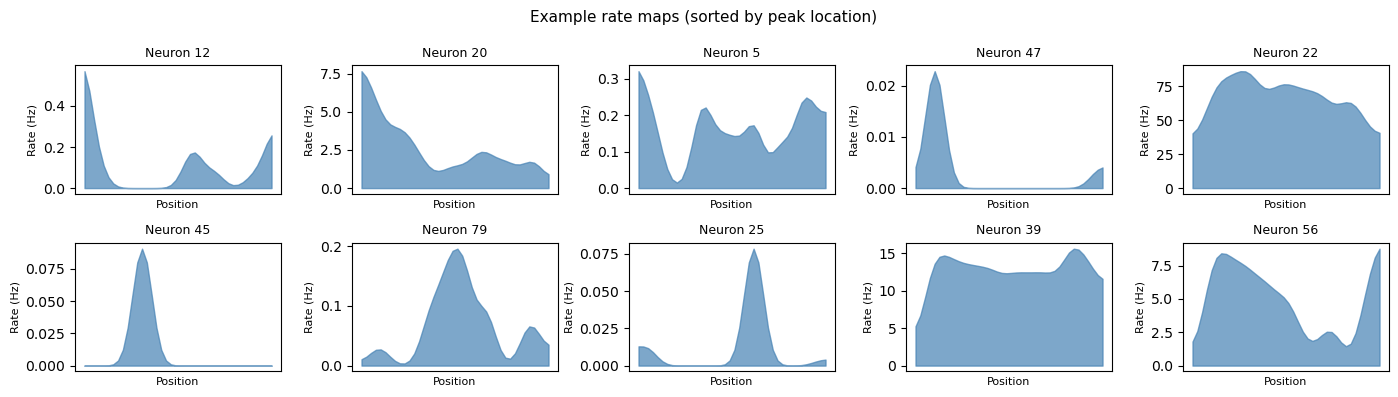

In [15]:
# Compute rate maps from raw spike counts and position
ratemaps, bin_centers = compute_ratemaps(
    spike_count_roi, position_roi,
    n_bins = 40, sigma = 2.0
)

print(f"Rate maps: {ratemaps.shape}  ({N} neurons × {ratemaps.shape[1]} position bins)")
print(f"Peak firing rates: min={ratemaps.max(axis=1).min():.2f}  "
      f"max={ratemaps.max(axis=1).max():.2f} Hz")

# Visualize a few rate maps
fig, axes = plt.subplots(2, 5, figsize=(14, 4))
peak_pos_order = np.argsort(ratemaps.argmax(axis=1))
example_neurons = peak_pos_order[np.linspace(0, N-1, 10, dtype=int)]

for ax, i in zip(axes.flat, example_neurons):
    ax.fill_between(bin_centers, ratemaps[i], alpha=0.7, color='steelblue')
    ax.set_title(f"Neuron {i}", fontsize=9)
    ax.set_xlabel("Position", fontsize=8)
    ax.set_ylabel("Rate (Hz)", fontsize=8)
    ax.set_xticks([])

fig.suptitle("Example rate maps (sorted by peak location)", fontsize=11)
plt.tight_layout()
plt.show()

In [16]:
n_silent = (np.linalg.norm(ratemaps, axis=1) == 0).sum()
print(f"Silent neurons (all-zero rate map): {n_silent} / {N}  "
      f"(excluded from correlation)")

rho_trained, p_trained = ratemap_correlation(E, ratemaps)
rho_random,  p_random  = ratemap_correlation(E_random, ratemaps)

print("Rate-map correlation (Spearman ρ between embedding distance and ratemap distance):")
print(f"  Trained E:  ρ = {rho_trained:+.3f}  (p = {p_trained:.3g})")
print(f"  Random  E:  ρ = {rho_random:+.3f}  (p = {p_random:.3g})")
print()
print("Interpretation:")
print("  ρ > 0: neurons close in E tend to have similar spatial tuning  [good]")
print("  ρ ≈ 0: embedding does not reflect spatial tuning geometry")
print("  ρ < 0: neurons close in E tend to have DISSIMILAR spatial tuning")

Silent neurons (all-zero rate map): 2 / 80  (excluded from correlation)
Rate-map correlation (Spearman ρ between embedding distance and ratemap distance):
  Trained E:  ρ = +0.552  (p = 1.02e-238)
  Random  E:  ρ = -0.021  (p = 0.259)

Interpretation:
  ρ > 0: neurons close in E tend to have similar spatial tuning  [good]
  ρ ≈ 0: embedding does not reflect spatial tuning geometry
  ρ < 0: neurons close in E tend to have DISSIMILAR spatial tuning


### Place Cell Enrichment

**Place cells** are neurons with a single strong spatial field — they fire a lot at one location and barely elsewhere. They are a functionally coherent group.

If E captures functional identity, place cells should be **more tightly clustered** in E than random chance.

`place_cell_enrichment(E, is_place_cell, n_perms=1000)` runs a permutation test:
1. Compute the observed mean pairwise distance among place cells in E.
2. Shuffle place-cell labels 1000 times and recompute the statistic.
3. Report the p-value: fraction of shuffles where the shuffled statistic ≤ observed.

**Small p-value (< 0.05):** place cells are more clustered than chance.

Place cells: 9 / 80  (11.2%)


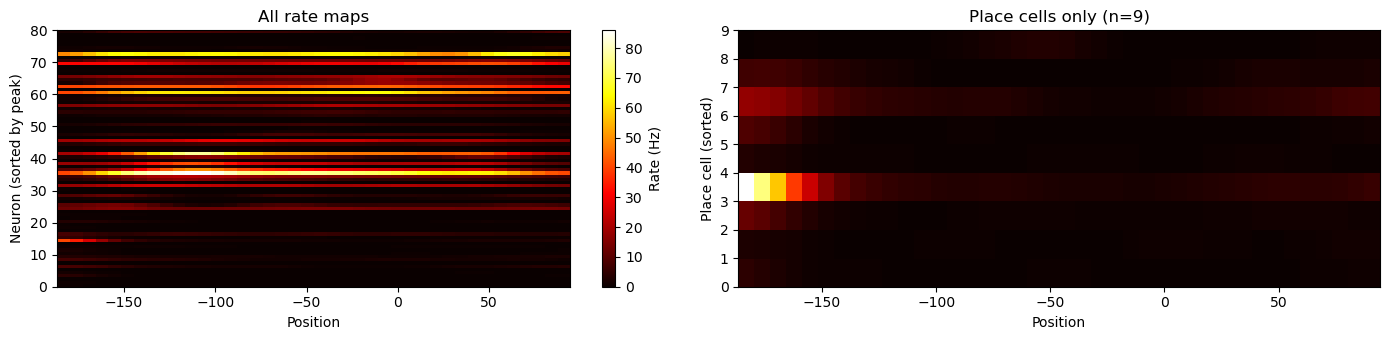

In [17]:
is_place_cell = identify_place_cells(ratemaps, min_peak_hz=1.0, peak_mean_ratio=3.0)

n_pc = is_place_cell.sum()
print(f"Place cells: {n_pc} / {N}  ({100*n_pc/N:.1f}%)")

# Visualize place cells vs. non-place cells
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))

peak_pos_order = np.argsort(ratemaps.argmax(axis=1))
im = axes[0].imshow(
    ratemaps[peak_pos_order], aspect='auto', origin='lower',
    extent=[bin_centers[0], bin_centers[-1], 0, N],
    cmap='hot'
)
axes[0].set_xlabel("Position"); axes[0].set_ylabel("Neuron (sorted by peak)")
axes[0].set_title("All rate maps")
plt.colorbar(im, ax=axes[0], label="Rate (Hz)")

pc_idx  = np.where(is_place_cell)[0]
npc_idx = np.where(~is_place_cell)[0]
axes[1].imshow(
    ratemaps[pc_idx[np.argsort(ratemaps[pc_idx].argmax(axis=1))]], aspect='auto',
    origin='lower', extent=[bin_centers[0], bin_centers[-1], 0, len(pc_idx)], cmap='hot'
)
axes[1].set_xlabel("Position"); axes[1].set_ylabel("Place cell (sorted)")
axes[1].set_title(f"Place cells only (n={n_pc})")

plt.tight_layout()
plt.show()

In [18]:
stat_trained, p_enrich_trained = place_cell_enrichment(E, is_place_cell, n_perms=1000, seed=0)
stat_random,  p_enrich_random  = place_cell_enrichment(E_random, is_place_cell, n_perms=1000, seed=0)

print("Place-cell enrichment (mean intra-class pairwise distance, lower = more clustered):")
print(f"  Trained E:  stat = {stat_trained:.4f}  p = {p_enrich_trained:.3f}")
print(f"  Random  E:  stat = {stat_random:.4f}  p = {p_enrich_random:.3f}")
print()
print("Interpretation:")
print("  p < 0.05: place cells are significantly more clustered than chance  [good]")
print("  p > 0.05: no significant enrichment")

Place-cell enrichment (mean intra-class pairwise distance, lower = more clustered):
  Trained E:  stat = 0.9556  p = 0.162
  Random  E:  stat = 1.4161  p = 0.667

Interpretation:
  p < 0.05: place cells are significantly more clustered than chance  [good]
  p > 0.05: no significant enrichment


### Split-Half Stability

If E captures stable neuron identity (not just transient co-firing patterns), training on two non-overlapping halves of the session should give consistent results.

`split_half_stability(E1, E2)` procedure:
1. Train Stage 2 on the first half of the session → `E1`.
2. Train Stage 2 on the second half → `E2`.
3. Apply orthogonal Procrustes alignment to find the best rotation mapping `E2` onto `E1`.
4. Return mean cosine similarity between aligned pairs — higher is more stable.

> Note: we reuse the Stage 1 model trained on the full session (frozen). Only Stage 2 is split.

In [19]:
T_half = T // 2

# Shorter config for split-half (fewer epochs to save time in tutorial)
unit_cfg_half = UnitTrainingConfig(
    epochs       = 50,
    lr           = 1e-3,
    d_u          = unit_cfg.d_u,
    m_units      = unit_cfg.m_units,
    temperature  = unit_cfg.temperature,
    lambda_coact = unit_cfg.lambda_coact,
    lambda_ctx   = unit_cfg.lambda_ctx,
    lambda_spike_ctx = unit_cfg.lambda_spike_ctx,
    lambda_lfp_ctx   = unit_cfg.lambda_lfp_ctx,
)

print("Training unit encoder on first half...")
unit_model_h1 = train_unit(
    latent_model,
    spike_count_roi[:T_half],
    sampling, unit_cfg_half,
    lfp = lfp_roi[:T_half],
)

print("\nTraining unit encoder on second half...")
unit_model_h2 = train_unit(
    latent_model,
    spike_count_roi[T_half:],
    sampling, unit_cfg_half,
    lfp = lfp_roi[T_half:],
)

E1 = unit_model_h1.embeddings().numpy()
E2 = unit_model_h2.embeddings().numpy()
print(f"\nE1: {E1.shape}   E2: {E2.shape}")

Training unit encoder on first half...


Stage 2: Unit Encoder: 100%|██████████| 50/50 [00:06<00:00,  7.20it/s, loss=2.3922, lr=0.00e+00]



Training unit encoder on second half...


Stage 2: Unit Encoder: 100%|██████████| 50/50 [00:06<00:00,  7.90it/s, loss=2.4724, lr=0.00e+00]


E1: (80, 8)   E2: (80, 8)


In [20]:
stab_trained = split_half_stability(E1, E2)
stab_random  = split_half_stability(
    F.normalize(torch.randn(N, unit_cfg.d_u), dim=-1).numpy(),
    F.normalize(torch.randn(N, unit_cfg.d_u), dim=-1).numpy(),
)

print("Split-half stability (mean cosine similarity after Procrustes alignment):")
print(f"  Trained E:  {stab_trained:.4f}")
print(f"  Random  E:  {stab_random:.4f}")
print(f"  Perfect  :   1.000  (E1 == E2 up to rotation)")
print()
print("Interpretation:")
print("  Closer to 1.0: the embedding geometry is reproducible across the session.")
print("  Close to 0.0:  the two halves produce inconsistent embeddings.")

Split-half stability (mean cosine similarity after Procrustes alignment):
  Trained E:  0.5858
  Random  E:  0.2033
  Perfect  :   1.000  (E1 == E2 up to rotation)

Interpretation:
  Closer to 1.0: the embedding geometry is reproducible across the session.
  Close to 0.0:  the two halves produce inconsistent embeddings.


### Nearest-Neighbour Purity

If cell-type labels are available (e.g., pyramidal vs. interneuron), we can ask: **do neurons of the same cell type cluster together in E?**

`nn_purity(E, labels, k=5)` computes, for each neuron, the fraction of its k nearest neighbors in E that share the same label. Mean over all neurons.

**Higher purity = cell types are separated in E.**

Here we use a simple proxy: fast-firing neurons (mean rate > threshold) are likely interneurons.

In [21]:
# Proxy cell-type label: high mean firing rate → likely interneuron
mean_rates_hz   = spike_rate_roi.mean(axis=0)          # [N]  mean Hz per neuron
threshold_hz    = np.percentile(mean_rates_hz, 75)     # top 25% = interneuron proxy
cell_type_label = (mean_rates_hz > threshold_hz).astype(int)   # 1 = interneuron, 0 = pyramidal

n_int = cell_type_label.sum()
print(f"Cell-type proxy (threshold={threshold_hz:.2f} Hz):")
print(f"  Putative interneurons: {n_int}  ({100*n_int/N:.1f}%)")
print(f"  Putative pyramidal:    {N-n_int}")

purity_trained = nn_purity(E,        cell_type_label, k=5)
purity_random  = nn_purity(E_random, cell_type_label, k=5)
chance         = max(n_int, N - n_int) / N   # majority-class chance level

print(f"\nNearest-neighbour purity (k=5):")
print(f"  Trained E:  {purity_trained:.3f}")
print(f"  Random  E:  {purity_random:.3f}")
print(f"  Chance:     {chance:.3f}  (always-predict majority class)")
print()
print("Interpretation:")
print("  Purity > chance: embedding separates cell types beyond what label frequency predicts.")

Cell-type proxy (threshold=5.14 Hz):
  Putative interneurons: 20  (25.0%)
  Putative pyramidal:    60

Nearest-neighbour purity (k=5):
  Trained E:  0.590
  Random  E:  0.597
  Chance:     0.750  (always-predict majority class)

Interpretation:
  Purity > chance: embedding separates cell types beyond what label frequency predicts.


### Visualize the Unit Embedding Space

Let's look at E directly — 2D PCA colored by different properties.

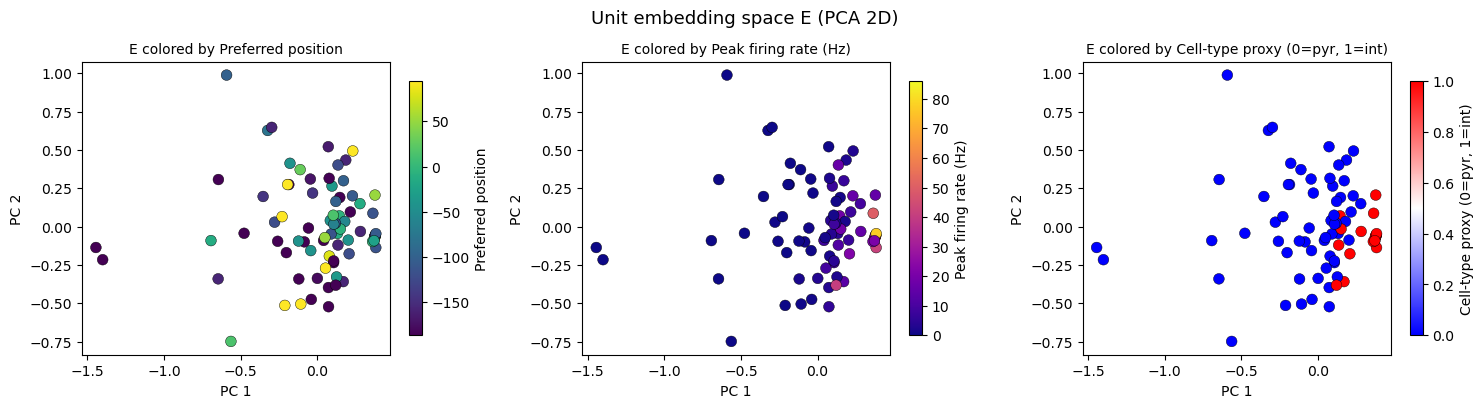

In [22]:
E_2d = PCA(n_components=2).fit_transform(E)   # [N, 2]

peak_location  = bin_centers[ratemaps.argmax(axis=1)]   # preferred position per neuron
peak_rate      = ratemaps.max(axis=1)                   # peak firing rate per neuron

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

props = [
    (peak_location,  'viridis', "Preferred position"),
    (peak_rate,      'plasma',  "Peak firing rate (Hz)"),
    (cell_type_label,'bwr',     "Cell-type proxy (0=pyr, 1=int)"),
]

for ax, (values, cmap, label) in zip(axes, props):
    sc = ax.scatter(E_2d[:, 0], E_2d[:, 1], c=values, cmap=cmap, s=60, edgecolors='k', lw=0.3)
    plt.colorbar(sc, ax=ax, label=label, shrink=0.8)
    ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
    ax.set_title(f"E colored by {label}", fontsize=10)
    ax.set_aspect('equal')

fig.suptitle("Unit embedding space E (PCA 2D)", fontsize=13)
plt.tight_layout()
plt.show()

### Summary

The cell below collects all evaluation scores into one table.

In [23]:
print("=" * 62)
print("UNIT EMBEDDING EVALUATION SUMMARY")
print("=" * 62)
print(f"{'Metric':<35} {'Trained E':>10} {'Random E':>10}")
print("-" * 62)
print(f"{'Ratemap correlation (ρ, ↑)':<35} {rho_trained:>+10.3f} {rho_random:>+10.3f}")
print(f"{'Place-cell enrichment (p, ↓)':<35} {p_enrich_trained:>10.3f} {p_enrich_random:>10.3f}")
print(f"{'Split-half stability (↑)':<35} {stab_trained:>10.3f} {stab_random:>10.3f}")
print(f"{'NN purity (k=5, ↑)':<35} {purity_trained:>10.3f} {purity_random:>10.3f}")
print("-" * 62)
print(f"  Place-cell fraction in data: {100*n_pc/N:.1f}%")
print(f"  Interneuron proxy fraction:  {100*n_int/N:.1f}%")
print(f"  Chance NN purity:            {100*chance:.1f}%")
print("=" * 62)

UNIT EMBEDDING EVALUATION SUMMARY
Metric                               Trained E   Random E
--------------------------------------------------------------
Ratemap correlation (ρ, ↑)              +0.552     -0.021
Place-cell enrichment (p, ↓)             0.162      0.667
Split-half stability (↑)                 0.586      0.203
NN purity (k=5, ↑)                       0.590      0.597
--------------------------------------------------------------
  Place-cell fraction in data: 11.2%
  Interneuron proxy fraction:  25.0%
  Chance NN purity:            75.0%


---
## Ablation A — Latent Encoder Quality

Holds the Stage 2 loss fixed and swaps out the latent `Z [T, D]` that drives the
context signal. Three conditions:

| # | Condition | Z context |
|---|-----------|----------|
| A1 | **PCA** | `PCA(spike_norm_roi, n_components=proj_dim)` — linear, spike-only |
| A2 | **α\_cross = 0** | Stage 1 retrained with no cross-modal loss — nonlinear, spike-only |
| A3 | **CoMETs (OG)** | Full Stage 1 (spikes + LFP, cross-modal) — reuse metrics above |

**A1 vs A3** — is the learned nonlinear trajectory better than linear PCA?  
**A2 vs A3** — does cross-modal (LFP) information in the latent help Stage 2?

In [24]:
from sklearn.decomposition import PCA as skPCA

proj_dim = latent_cfg.proj_dim   # match Stage 1 output dimension

# A1 — PCA context: linear projection of spike_norm_roi, same shape as Z_spikes
pca = skPCA(n_components=proj_dim, random_state=0)
Z_pca = pca.fit_transform(spike_norm_roi)   # [T, proj_dim]
print(f"PCA Z: {Z_pca.shape}  "
      f"({pca.explained_variance_ratio_.sum()*100:.1f}% variance explained)")

# A2 — Retrain Stage 1 with alpha_cross=0 (spike-only latent, no LFP cross-modal)
print(f"\nRetraining Stage 1 with alpha_cross=0 ({latent_cfg.epochs} epochs)...")
latent_cfg_nocross = LatentTrainingConfig(
    epochs      = latent_cfg.epochs,
    lr          = latent_cfg.lr,
    temperature = latent_cfg.temperature,
    weight_decay= latent_cfg.weight_decay,
    proj_dim    = latent_cfg.proj_dim,
    alpha_cross = 0.0,   # <-- no cross-modal signal
    beta        = latent_cfg.beta,
    head_cls    = latent_cfg.head_cls,
)
latent_model_nocross = train_latent(
    spike_norm_roi, modA,
    lfp_roi,        modB,
    sampling, latent_cfg_nocross,
)
print("Stage 1 (alpha_cross=0) done.")

PCA Z: (15000, 8)  (36.6% variance explained)

Retraining Stage 1 with alpha_cross=0 (100 epochs)...


Stage 1: Latent Encoder: 100%|██████████| 100/100 [00:49<00:00,  2.02it/s, total=4.7376, within=4.7376, cross=5.7687, lr=0.00e+00]

Stage 1 (alpha_cross=0) done.


In [25]:
from comets.unit_eval import ratemap_correlation, place_cell_enrichment, nn_purity

def _eval_enc(unit_enc):
    """Evaluate a UnitEncoder on the three fast metrics."""
    E_ = unit_enc.embeddings().numpy()
    rho, _ = ratemap_correlation(E_, ratemaps)
    _, p_en = place_cell_enrichment(E_, is_place_cell, n_perms=500, seed=42)
    pur = nn_purity(E_, cell_type_label, k=5)
    return rho, p_en, pur

# A1 — Stage 2 with PCA latent as context (z_spikes=Z_pca bypasses embed_latent_spikes)
print("[A1/3] Stage 2 — PCA latent...")
enc_A1 = train_unit(
    latent_model, spike_count_roi, sampling, unit_cfg,
    z_spikes=Z_pca,   # bypass latent_model.embed_latent_spikes()
)
res_A1 = _eval_enc(enc_A1)
print(f"  ρ={res_A1[0]:+.3f}  p_enrich={res_A1[1]:.3f}  purity={res_A1[2]:.3f}")

# A2 — Stage 2 with alpha_cross=0 latent
print("\n[A2/3] Stage 2 — alpha_cross=0 latent...")
enc_A2 = train_unit(
    latent_model_nocross, spike_count_roi, sampling, unit_cfg,
    lfp=lfp_roi,
)
res_A2 = _eval_enc(enc_A2)
print(f"  ρ={res_A2[0]:+.3f}  p_enrich={res_A2[1]:.3f}  purity={res_A2[2]:.3f}")

# A3 — Full CoMETs: reuse metrics already computed above
print("\n[A3/3] Full CoMETs (reusing metrics from main evaluation).")
res_A3 = (rho_trained, p_enrich_trained, purity_trained)

W = 72
print("\n" + "=" * W)
print("ABLATION A — Latent Encoder Quality")
print("=" * W)
print(f"{'Metric':<35} {'PCA (A1)':>10} {'α_cross=0 (A2)':>14} {'CoMETs (A3)':>11}")
print("-" * W)
print(f"{'Ratemap correlation (ρ, ↑)':<35} {res_A1[0]:>+10.3f} {res_A2[0]:>+14.3f} {res_A3[0]:>+11.3f}")
print(f"{'Place-cell enrichment (p, ↓)':<35} {res_A1[1]:>10.3f} {res_A2[1]:>14.3f} {res_A3[1]:>11.3f}")
print(f"{'NN purity (k=5, ↑)':<35} {res_A1[2]:>10.3f} {res_A2[2]:>14.3f} {res_A3[2]:>11.3f}")
print("-" * W)
print("Key comparisons:")
print("  A1 vs A3 — is the nonlinear learned trajectory better than linear PCA?")
print("  A2 vs A3 — does cross-modal (LFP) information in the latent help?")
print("  A2 vs A1 — does any latent training beat the linear baseline?")
print("=" * W)

[A1/3] Stage 2 — PCA latent...


Stage 2: Unit Encoder: 100%|██████████| 100/100 [00:24<00:00,  4.10it/s, loss=3.6150, lr=0.00e+00] 


  ρ=+0.553  p_enrich=0.108  purity=0.617

[A2/3] Stage 2 — alpha_cross=0 latent...


Stage 2: Unit Encoder: 100%|██████████| 100/100 [00:18<00:00,  5.28it/s, loss=2.6084, lr=0.00e+00]


  ρ=+0.570  p_enrich=0.130  purity=0.607

[A3/3] Full CoMETs (reusing metrics from main evaluation).

ABLATION A — Latent Encoder Quality
Metric                                PCA (A1) α_cross=0 (A2) CoMETs (A3)
------------------------------------------------------------------------
Ratemap correlation (ρ, ↑)              +0.553         +0.570      +0.552
Place-cell enrichment (p, ↓)             0.108          0.130       0.162
NN purity (k=5, ↑)                       0.617          0.607       0.590
------------------------------------------------------------------------
Key comparisons:
  A1 vs A3 — is the nonlinear learned trajectory better than linear PCA?
  A2 vs A3 — does cross-modal (LFP) information in the latent help?
  A2 vs A1 — does any latent training beat the linear baseline?


---
## Ablation B — Loss Component Grid

Holds the latent fixed (full CoMETs Z from Stage 1) and varies which Stage 2
loss terms are active.

| # | Condition | λ\_coact | λ\_spike\_ctx | λ\_lfp\_ctx |
|---|-----------|---------|-------------|----------|
| B1 | **Coact-only** | 1 | 0 | 0 |
| B2 | **Spike ctx only** | 0 | 1 | 0 |
| B3 | **LFP ctx only** | 0 | 0 | 1 |
| B4 | **Full (OG)** | 1 | 1 | 1 | ← reuse |

**B1 vs B4** — does the context loss add value over raw co-activity alone?  
**B2 vs B3** — which modality's context signal is more informative?  
**B2 + B3 vs B4** — does combining both modalities help?

In [26]:
# Each tuple: (label, UnitTrainingConfig kwargs, lfp arg for train_unit)
# lfp=None when lambda_lfp_ctx=0 to skip the LFP embedding forward pass.
conditions_B = [
    (
        "Coact-only   (B1)",
        dict(lambda_coact=1.0, lambda_ctx=0.0,
             lambda_spike_ctx=0.0, lambda_lfp_ctx=0.0),
        None,        # no LFP needed (ctx is zeroed)
    ),
    (
        "Spike ctx    (B2)",
        dict(lambda_coact=0.0, lambda_ctx=1.0,
             lambda_spike_ctx=1.0, lambda_lfp_ctx=0.0),
        None,        # LFP context weight = 0; skip embed_latent_lfp
    ),
    (
        "LFP ctx      (B3)",
        dict(lambda_coact=0.0, lambda_ctx=1.0,
             lambda_spike_ctx=0.0, lambda_lfp_ctx=1.0),
        lfp_roi,     # needs Z_lfp
    ),
]

results_B = []
for name, kw, lfp_arg in conditions_B:
    print(f"\n[{name}]...")
    _cfg = UnitTrainingConfig(
        epochs=unit_cfg.epochs, lr=unit_cfg.lr,
        d_u=unit_cfg.d_u, m_units=unit_cfg.m_units,
        temperature=unit_cfg.temperature,
        **kw,
    )
    enc = train_unit(latent_model, spike_count_roi, sampling, _cfg, lfp=lfp_arg)
    res = _eval_enc(enc)
    results_B.append((name, res))
    print(f"  ρ={res[0]:+.3f}  p_enrich={res[1]:.3f}  purity={res[2]:.3f}")

# B4 — Full (OG): reuse existing metrics
results_B.append(("Full         (B4)", (rho_trained, p_enrich_trained, purity_trained)))

W = 72
print("\n" + "=" * W)
print("ABLATION B — Loss Component Grid")
print("=" * W)
print(f"{'Condition':<25} {'ρ (↑)':>10} {'p_enrich (↓)':>13} {'purity (↑)':>10}")
print("-" * W)
for name, (rho, p_en, pur) in results_B:
    print(f"{name:<25} {rho:>+10.3f} {p_en:>13.3f} {pur:>10.3f}")
print("-" * W)
print("Key comparisons:")
print("  B1 vs B4 — ctx loss adds value beyond raw co-activity?")
print("  B2 vs B3 — spike vs LFP context: which signal is more informative?")
print("  B2+B3 vs B4 — combining both modalities: additive or redundant?")
print("=" * W)


[Coact-only   (B1)]...


Stage 2: Unit Encoder: 100%|██████████| 100/100 [00:15<00:00,  6.56it/s, loss=2.1504, lr=0.00e+00]


  ρ=+0.248  p_enrich=0.204  purity=0.762

[Spike ctx    (B2)]...


Stage 2: Unit Encoder: 100%|██████████| 100/100 [00:18<00:00,  5.55it/s, loss=0.7033, lr=0.00e+00]


  ρ=+0.575  p_enrich=0.112  purity=0.623

[LFP ctx      (B3)]...


Stage 2: Unit Encoder: 100%|██████████| 100/100 [00:18<00:00,  5.33it/s, loss=1.0129, lr=0.00e+00]

  ρ=+0.592  p_enrich=0.114  purity=0.647

ABLATION B — Loss Component Grid
Condition                      ρ (↑)  p_enrich (↓) purity (↑)
------------------------------------------------------------------------
Coact-only   (B1)             +0.248         0.204      0.762
Spike ctx    (B2)             +0.575         0.112      0.623
LFP ctx      (B3)             +0.592         0.114      0.647
Full         (B4)             +0.552         0.162      0.590
------------------------------------------------------------------------
Key comparisons:
  B1 vs B4 — ctx loss adds value beyond raw co-activity?
  B2 vs B3 — spike vs LFP context: which signal is more informative?
  B2+B3 vs B4 — combining both modalities: additive or redundant?
